# Analyzing ensembles of persistence results

A finite encoding lets us ask the same question at original parameter values across different inputs. Repeating that computation raises another question: how much do the answers vary? A mean alone hides that variation, while a shaded band needs a precise interpretation.

This guide starts with ordinary diagrams whose answers can be checked by hand, then compares dimension fields from finite modules. Finally it distinguishes empirical spread from uncertainty about a population mean. Familiarity with [ordinary persistence](../ordinary_persistence.md) is enough for the first example. Install TamerOp and CairoMakie to execute the figures; WGLMakie is needed only for live controls.


In [1]:
using TamerOp, CairoMakie
A = TamerOp.Advanced
V = TamerOp.Visualization
CairoMakie.activate!()

## Repeat the same observable

Take three single intervals with deaths 2, 4 and 6. A first persistence landscape is a tent: its height at parameter $t$ is $\max(0,\min(t-b,d-t))$. Each interval therefore gives a different function on the same parameter axis. We have supplied three deterministic fixtures, so the first band will describe these fixtures without making a population claim.


In [2]:
diagrams = [PersistenceDiagram([[(0., death)]], [Float64[]]) for death in (2.,4.,6.)]
ensemble = persistence_ensemble(diagrams; grid=[0.,1.,2.,3.,4.,6.],
    sample_ids=["short","middle","long"], protocol="Three supplied intervals",
    population="These three illustrative results")
ensemble_summary(ensemble)

(kind = :persistence_ensemble, samples = 3, probes = 6, shape = (6,), context = (statistic = "Ordinary persistence landscape", protocol = "Three supplied intervals", population = "These three illustrative results", sampling = :descriptive, units = "parameter", axis_labels = ("Parameter 1",), degree = 0, field = "TamerOp.CoreModules.CoeffFields.PrimeField(2)", layer = 1, normalization = "none", essential = "error; counts per replicate [0, 0, 0]; sublevel"), missing = 0)

At parameter 2 the heights are 0, 2 and 2, so their mean is $4/3$. The observed range is $[0,2]$. The range tells us what happened in these repeats; it is not a confidence interval for an unknown mean. Essential intervals require an explicit policy because their treatment changes the observable.


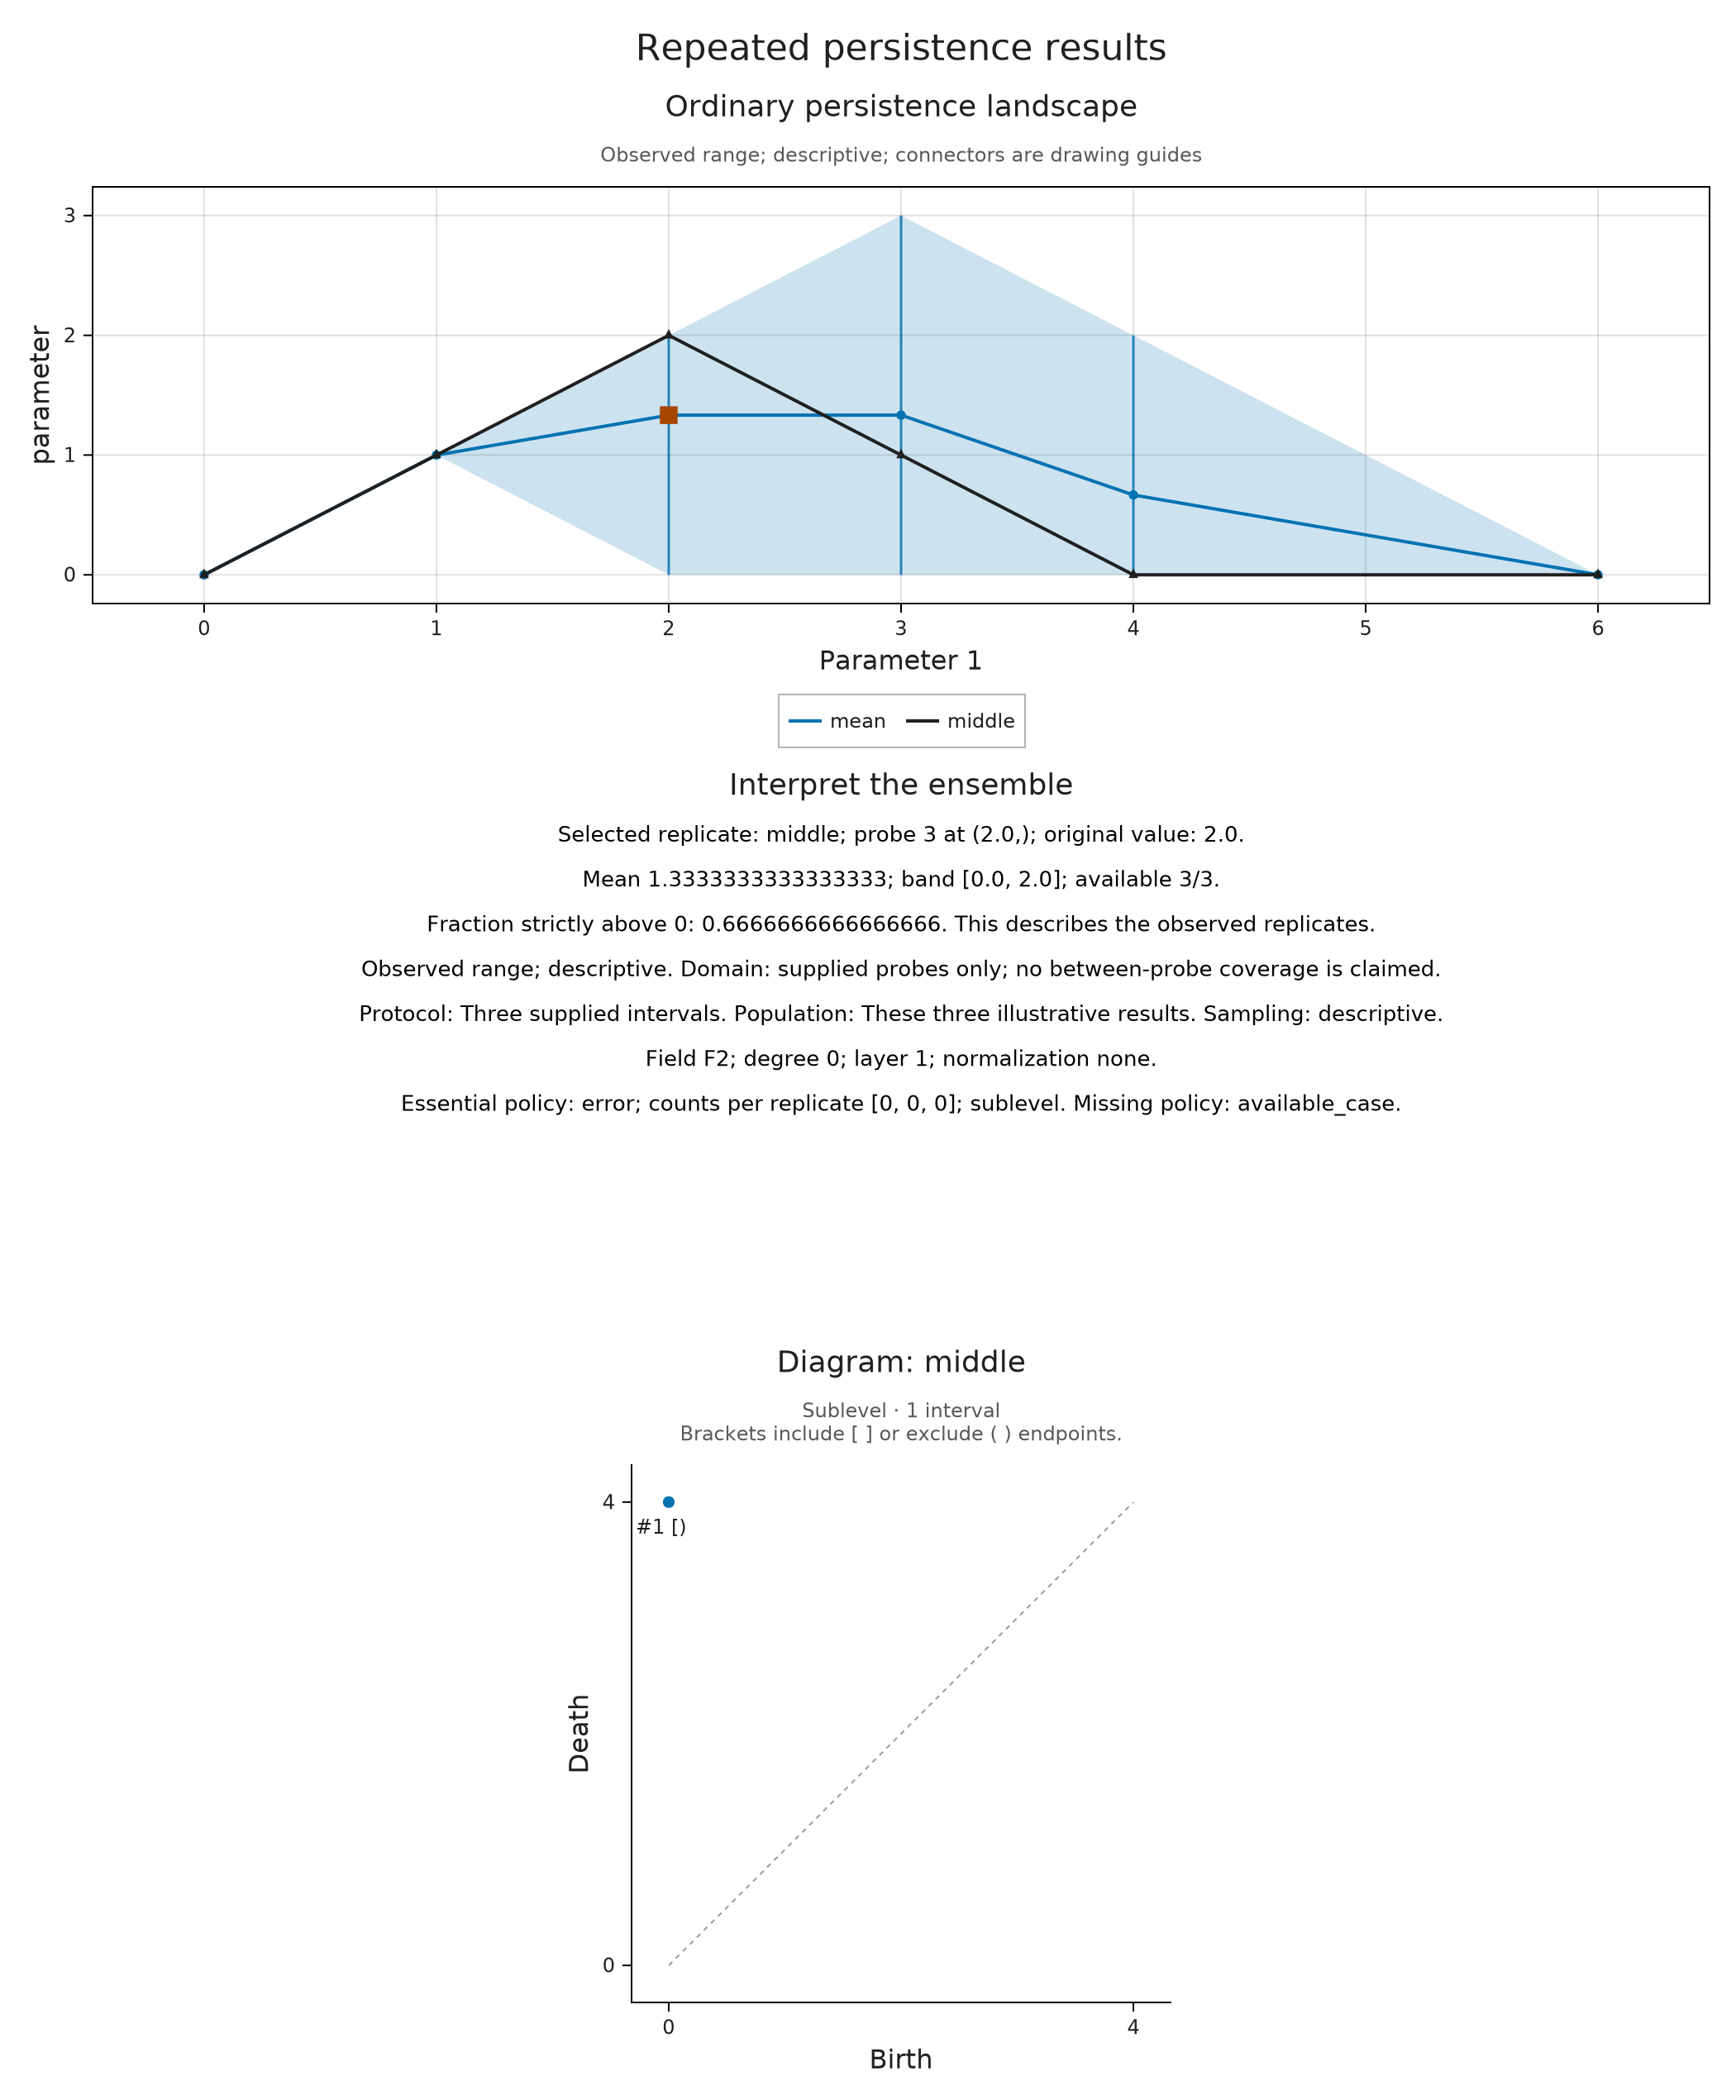

In [3]:
spread = summarize_ensemble(ensemble; band=:range)
values = ensemble_values(spread)
@assert values.mean[3] ≈ 4/3
@assert (values.lower[3], values.upper[3]) == (0.,2.)
visualize(spread; sample="middle", probe=3)

Markers identify the actual probes. Connecting lines and shading help read the sampled values; they do not certify behavior between probes. Requesting diagram facets makes the individual observations visible without assigning identities between their bars.


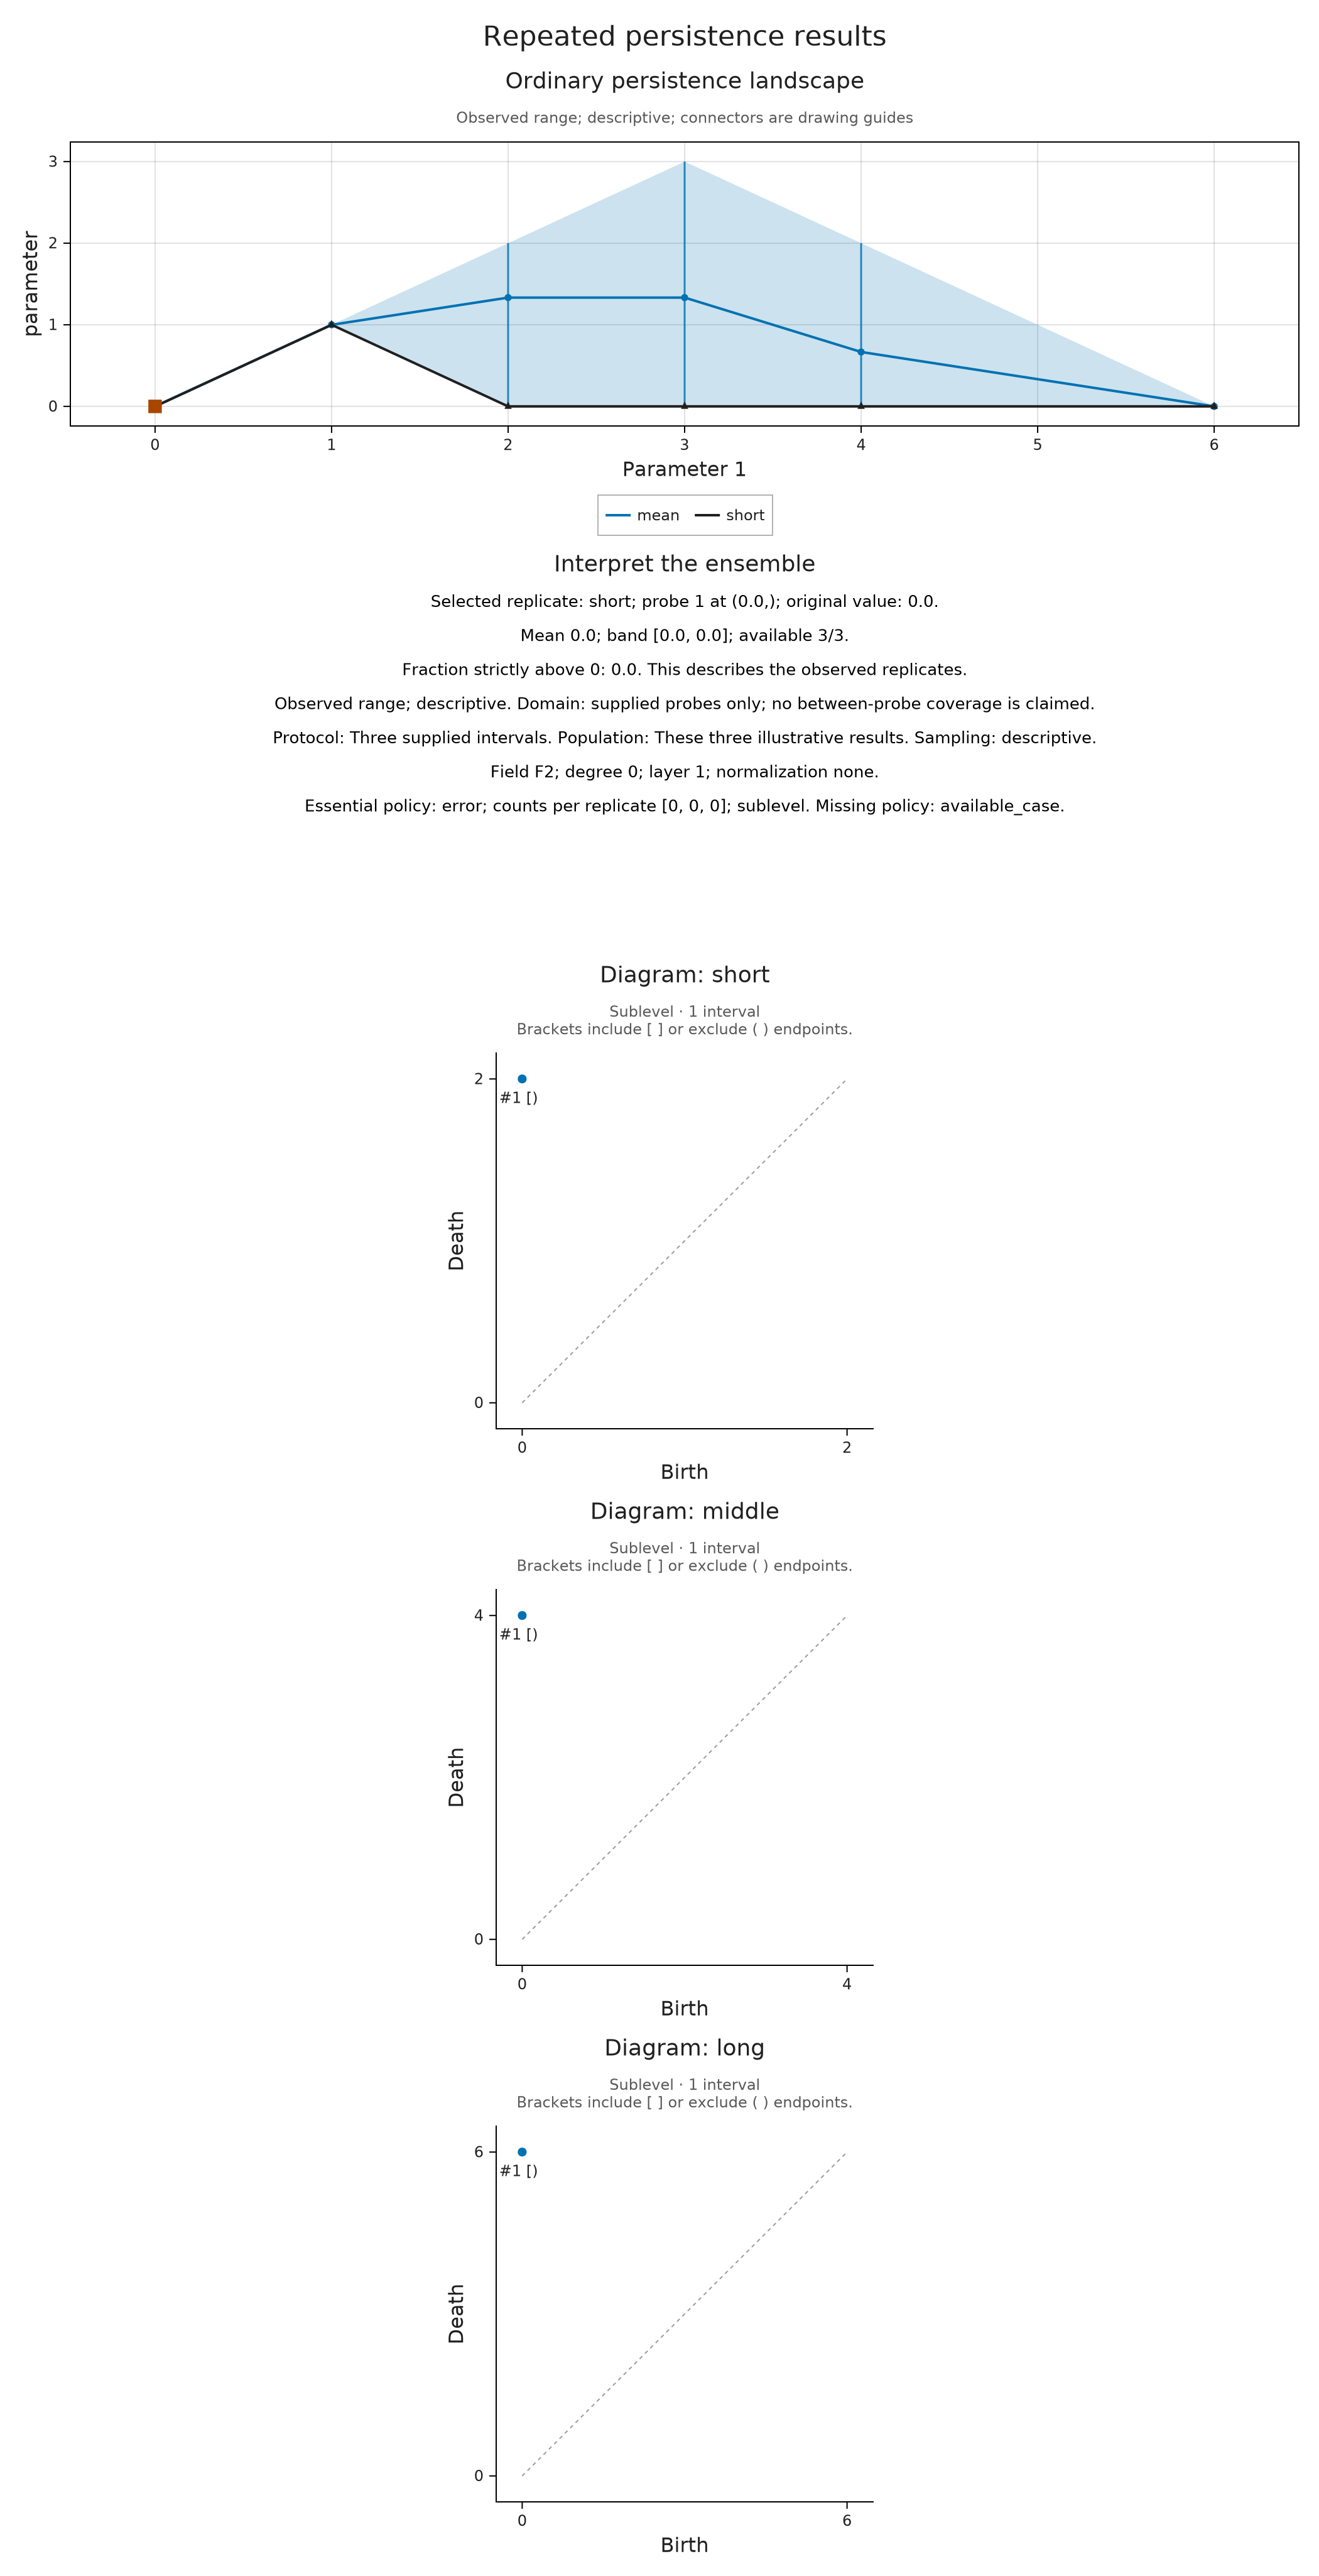

In [4]:
visualize(spread; diagram_samples=(1,2,3))

## Read support frequencies

A frequency answers a different question: what fraction of the observed replicates has a value strictly above a chosen threshold? With the default threshold zero, the answer at parameter 2 is $2/3$. This is an empirical frequency, not a significance level or an estimated probability with an automatic confidence guarantee.


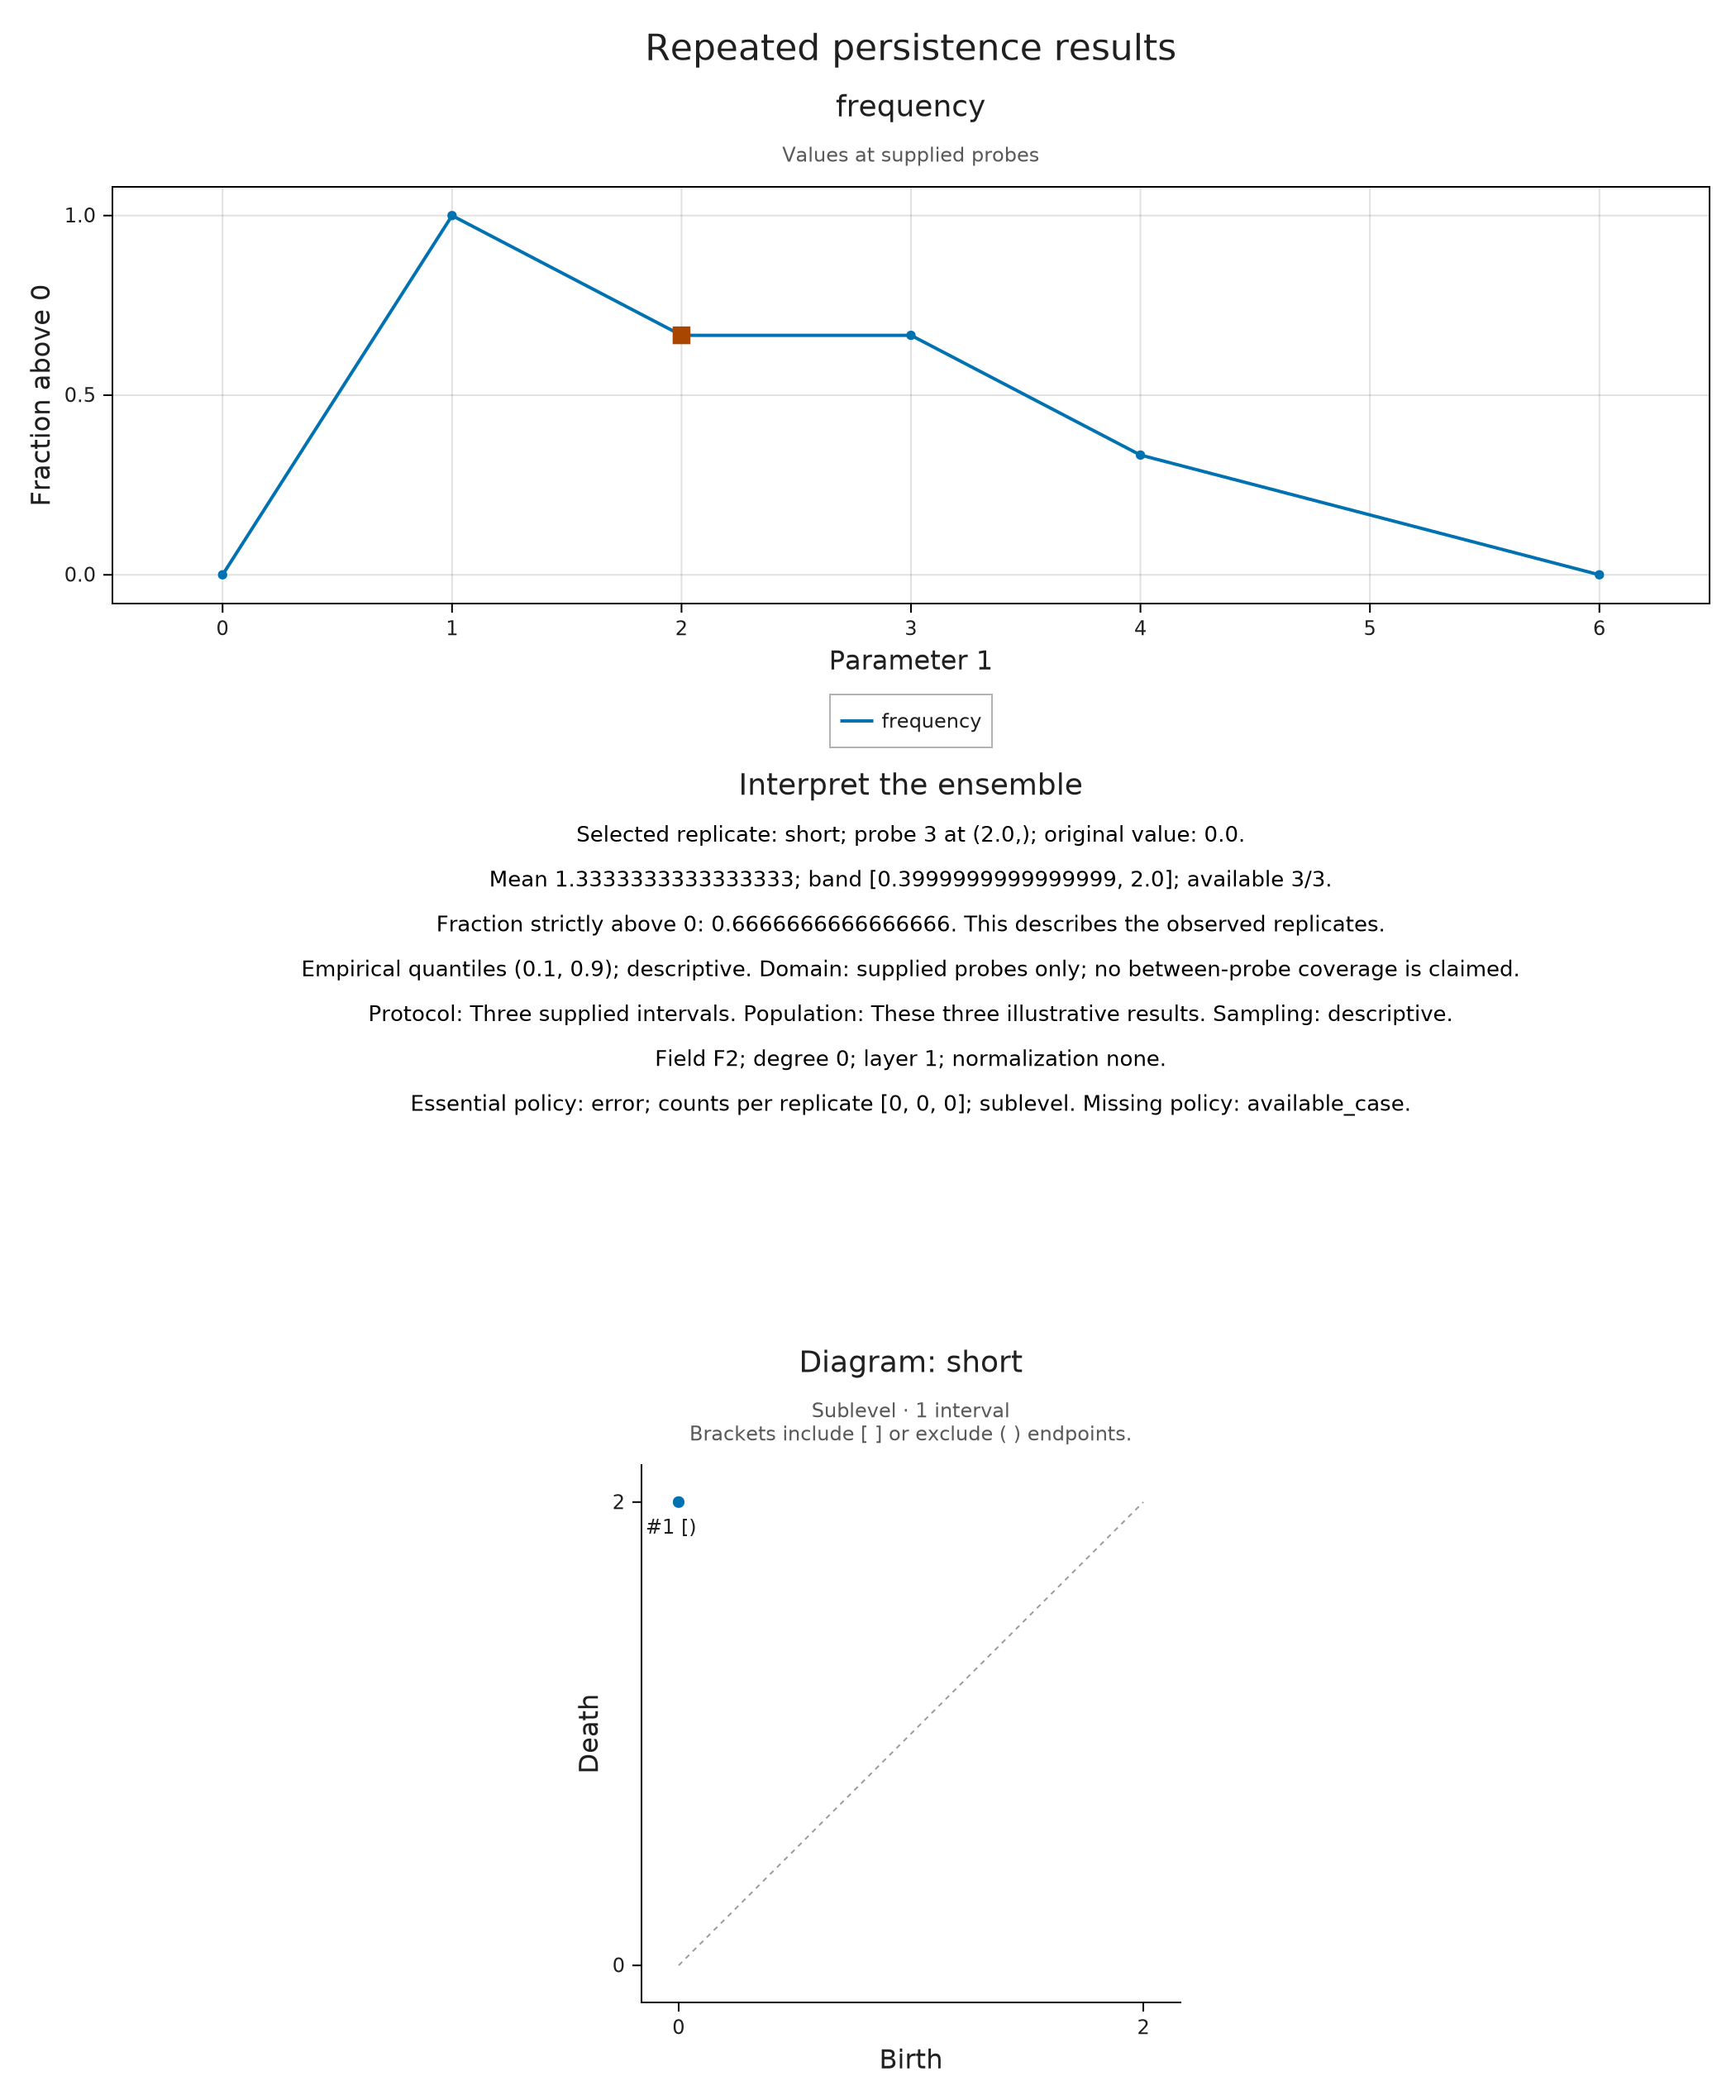

In [5]:
frequency = summarize_ensemble(ensemble; threshold=0)
@assert ensemble_values(frequency).frequency[3] == 2/3
visualize(frequency; view=:frequency, probe=3)

Exercise: raise the threshold to 1. What happens at parameter 1? All three heights equal 1, so the strict comparison makes the new frequency zero.


In [6]:
above_one = summarize_ensemble(ensemble; threshold=1)
@assert ensemble_values(above_one).frequency[2] == 0

## Compare finite modules at shared original parameters

The same ensemble operation accepts dimension, rank, or other scalar queries from finite encodings. The columns must represent the same mathematical queries, even when the encodings have different finite labels. Do not align unrelated poset vertex numbers.

Here two finite modules are encoded over the same two-dimensional grid. Their only nonzero stalk is the first grid label, with dimensions one and two. All other stalks and structure maps are zero. This supplies a small algebraic example independently of a filtered point cloud.


In [7]:
P = TamerOp.FiniteFringe.ProductOfChainsPoset((2,2))
pi = TamerOp.EncodingCore.GridEncodingMap(P,([0,3],[0,5]))
dims1, dims2 = [1,0,0,0], [2,0,0,0]
M1 = TamerOp.Modules.PModule{QQ}(P,dims1,Dict(e=>zeros(QQ,dims1[e[2]],dims1[e[1]]) for e in TamerOp.FiniteFringe.cover_edges(P));field=TamerOp.CoreModules.QQField())
M2 = TamerOp.Modules.PModule{QQ}(P,dims2,Dict(e=>zeros(QQ,dims2[e[2]],dims2[e[1]]) for e in TamerOp.FiniteFringe.cover_edges(P));field=TamerOp.CoreModules.QQField())
encoded = [TamerOp.EncodingResult(P,M1,pi), TamerOp.EncodingResult(P,M2,pi)]

2-element Vector{EncodingResult{TamerOp.FiniteFringe.ProductOfChainsPoset{2}, TamerOp.Modules.PModule{Rational{BigInt}, TamerOp.CoreModules.CoeffFields.QQField, Matrix{Rational{BigInt}}, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, Nothing, Nothing, @NamedTuple{}}}:
 EncodingResult(backend=auto, module_type=PModule, compiled=false, materialized=true)
 EncodingResult(backend=auto, module_type=PModule, compiled=false, materialized=true)

Query the classifier at each original parameter pair, then query the corresponding stalk. The display adapter records those physical coordinates. Its cells show samples, not a reconstruction of the exact classifier regions.


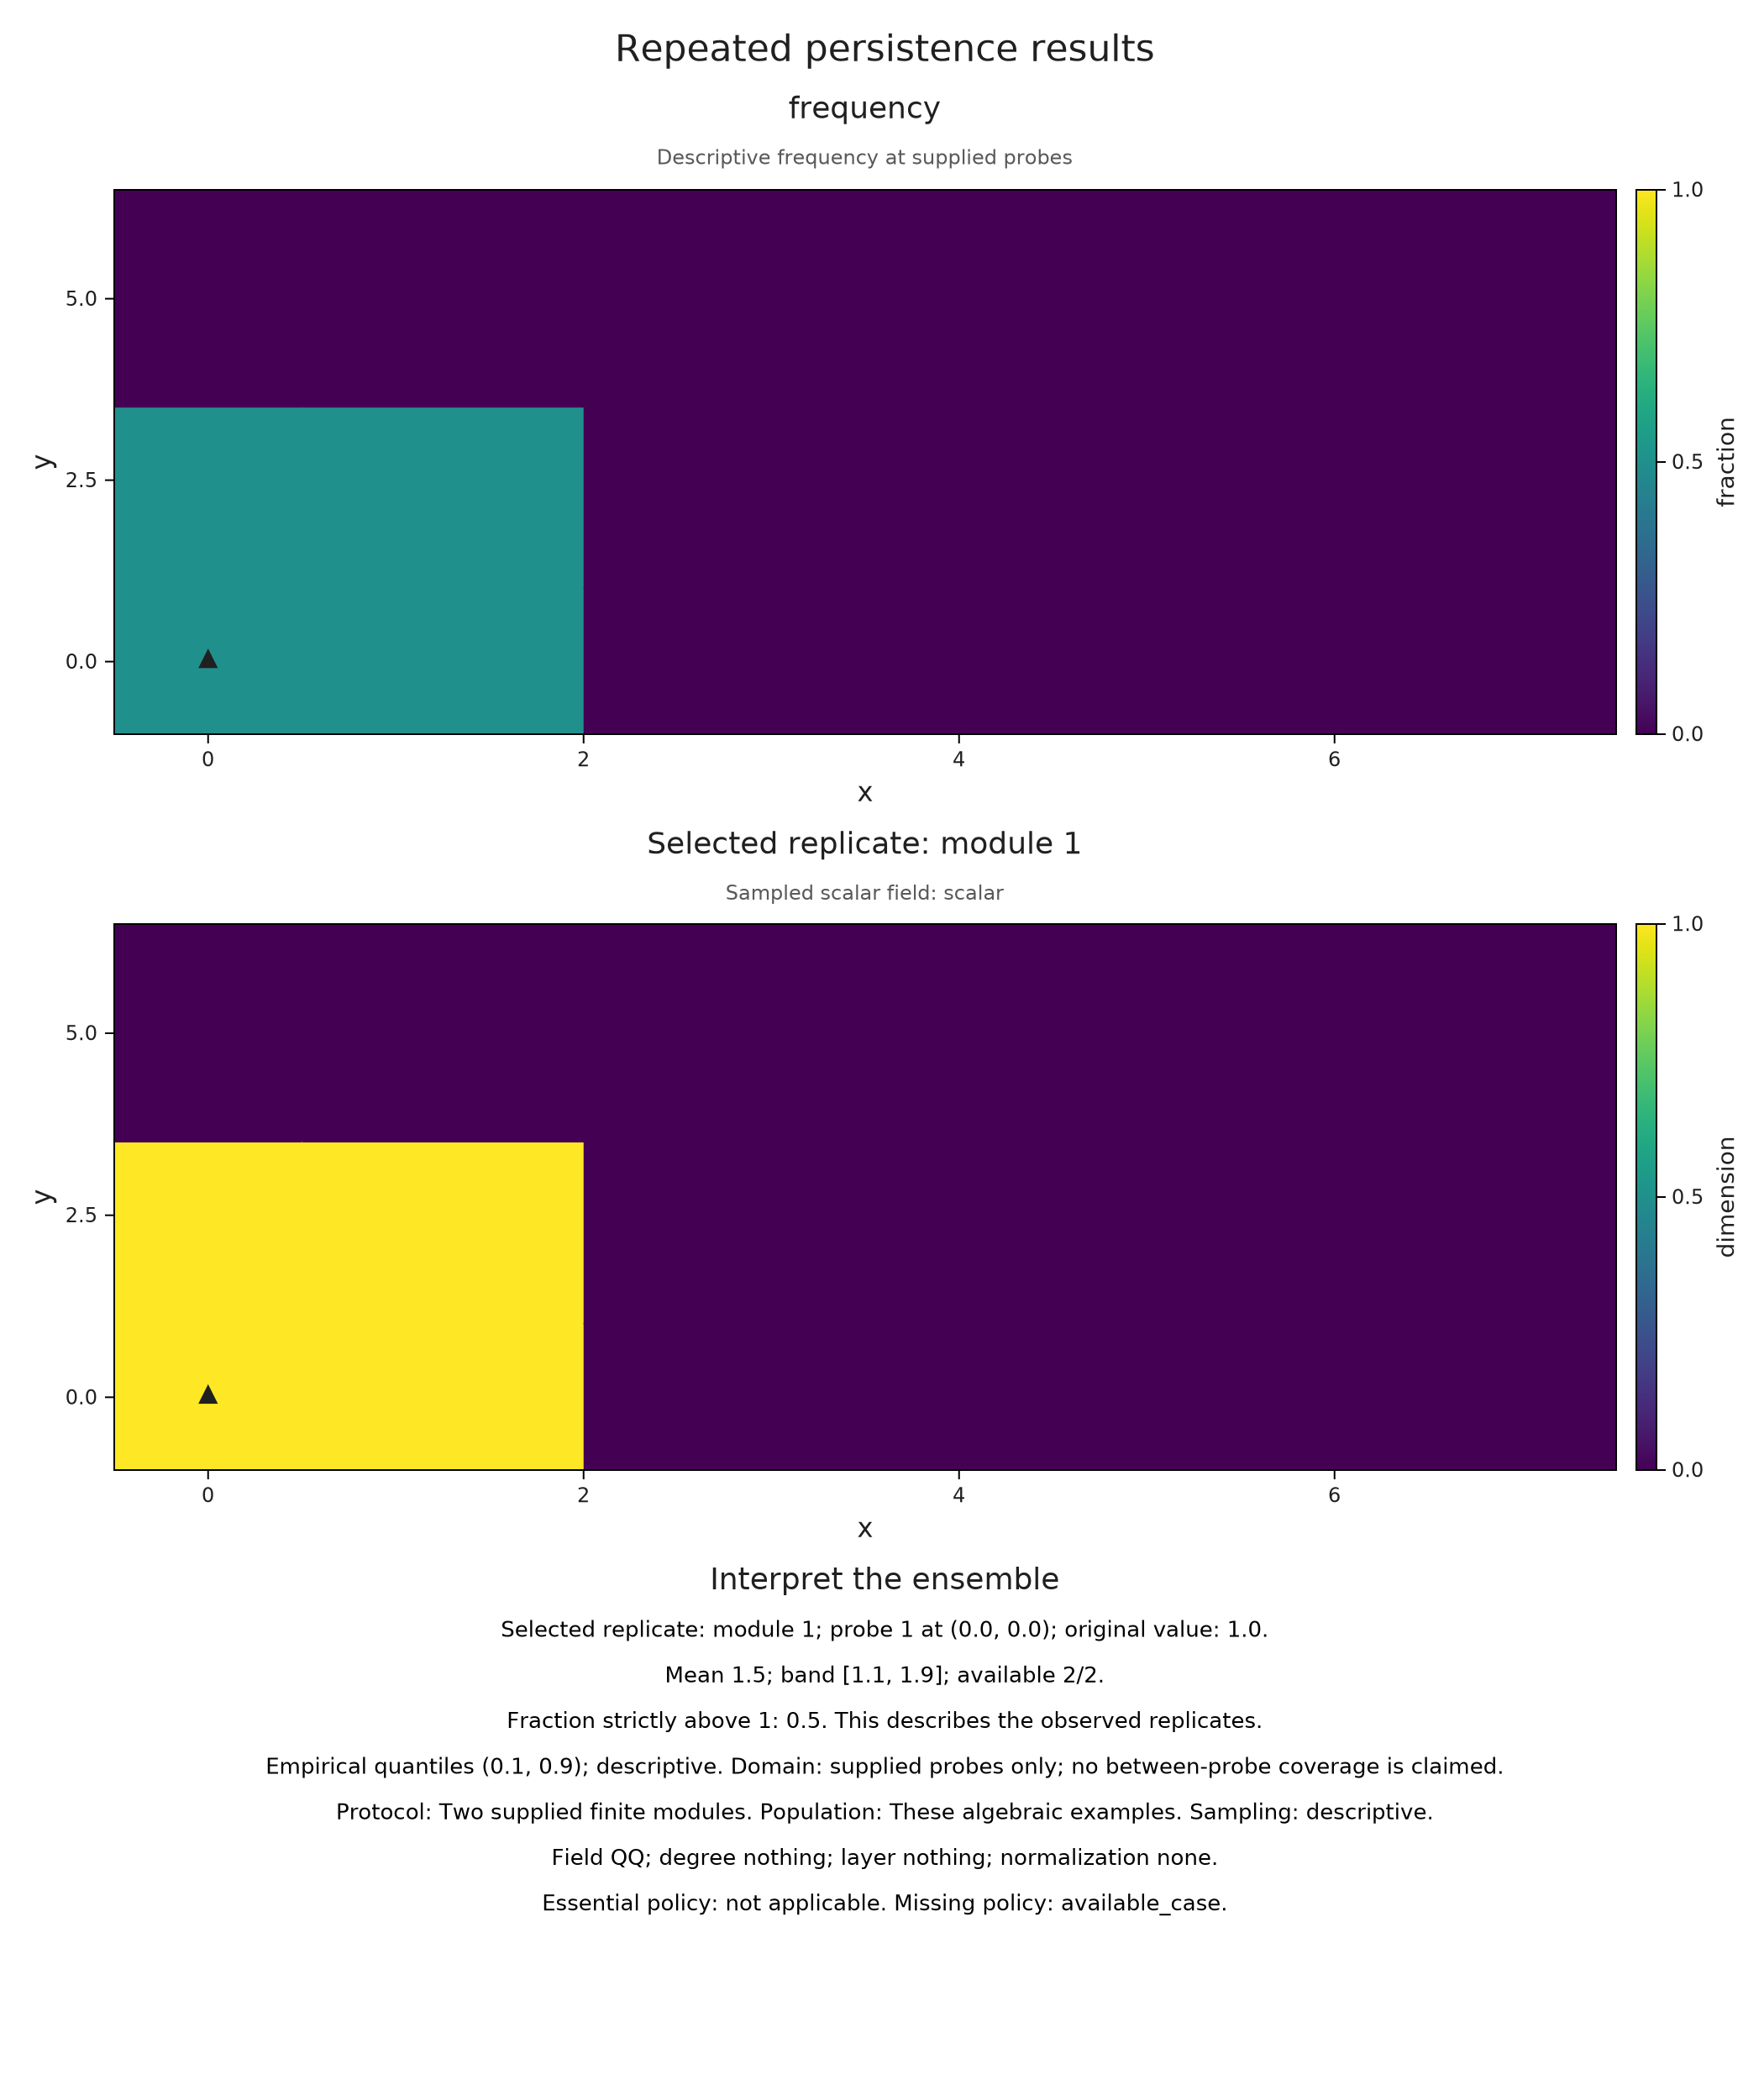

In [8]:
xgrid, ygrid = [0.,1.,3.,6.], [0.,2.,5.]
fields = [ScalarField((xgrid,ygrid),
    [A.dim_at(encoding_module(enc), A.locate(encoding_map(enc),(x,y))) for x in xgrid, y in ygrid];
    id="module $i", units="dimension", axis_labels=("x","y")) for (i,enc) in enumerate(encoded)]
module_ensemble = persistence_ensemble(fields; protocol="Two supplied finite modules",
    population="These algebraic examples", field="QQ")
module_spread = summarize_ensemble(module_ensemble; threshold=1)
@assert ensemble_values(module_spread).mean[1,1] == 1.5
@assert ensemble_values(module_spread).frequency[1,1] == 0.5
visualize(module_spread; view=:frequency)

## When a mean band supports inference

Inference needs a sampling model. Suppose each row is an independent draw from the same declared population, the probes were fixed in advance, and every observable is known to lie in $[0,3]$. For example, the first landscape of an interval contained in $[0,6]$ has height at most 3. This bound comes from the construction, not the observed maximum.

The following small sample illustrates that contract. Selecting `sampling=:iid` records an assertion you must justify for your own data. Perturbing one subject repeatedly does not create independent subjects.


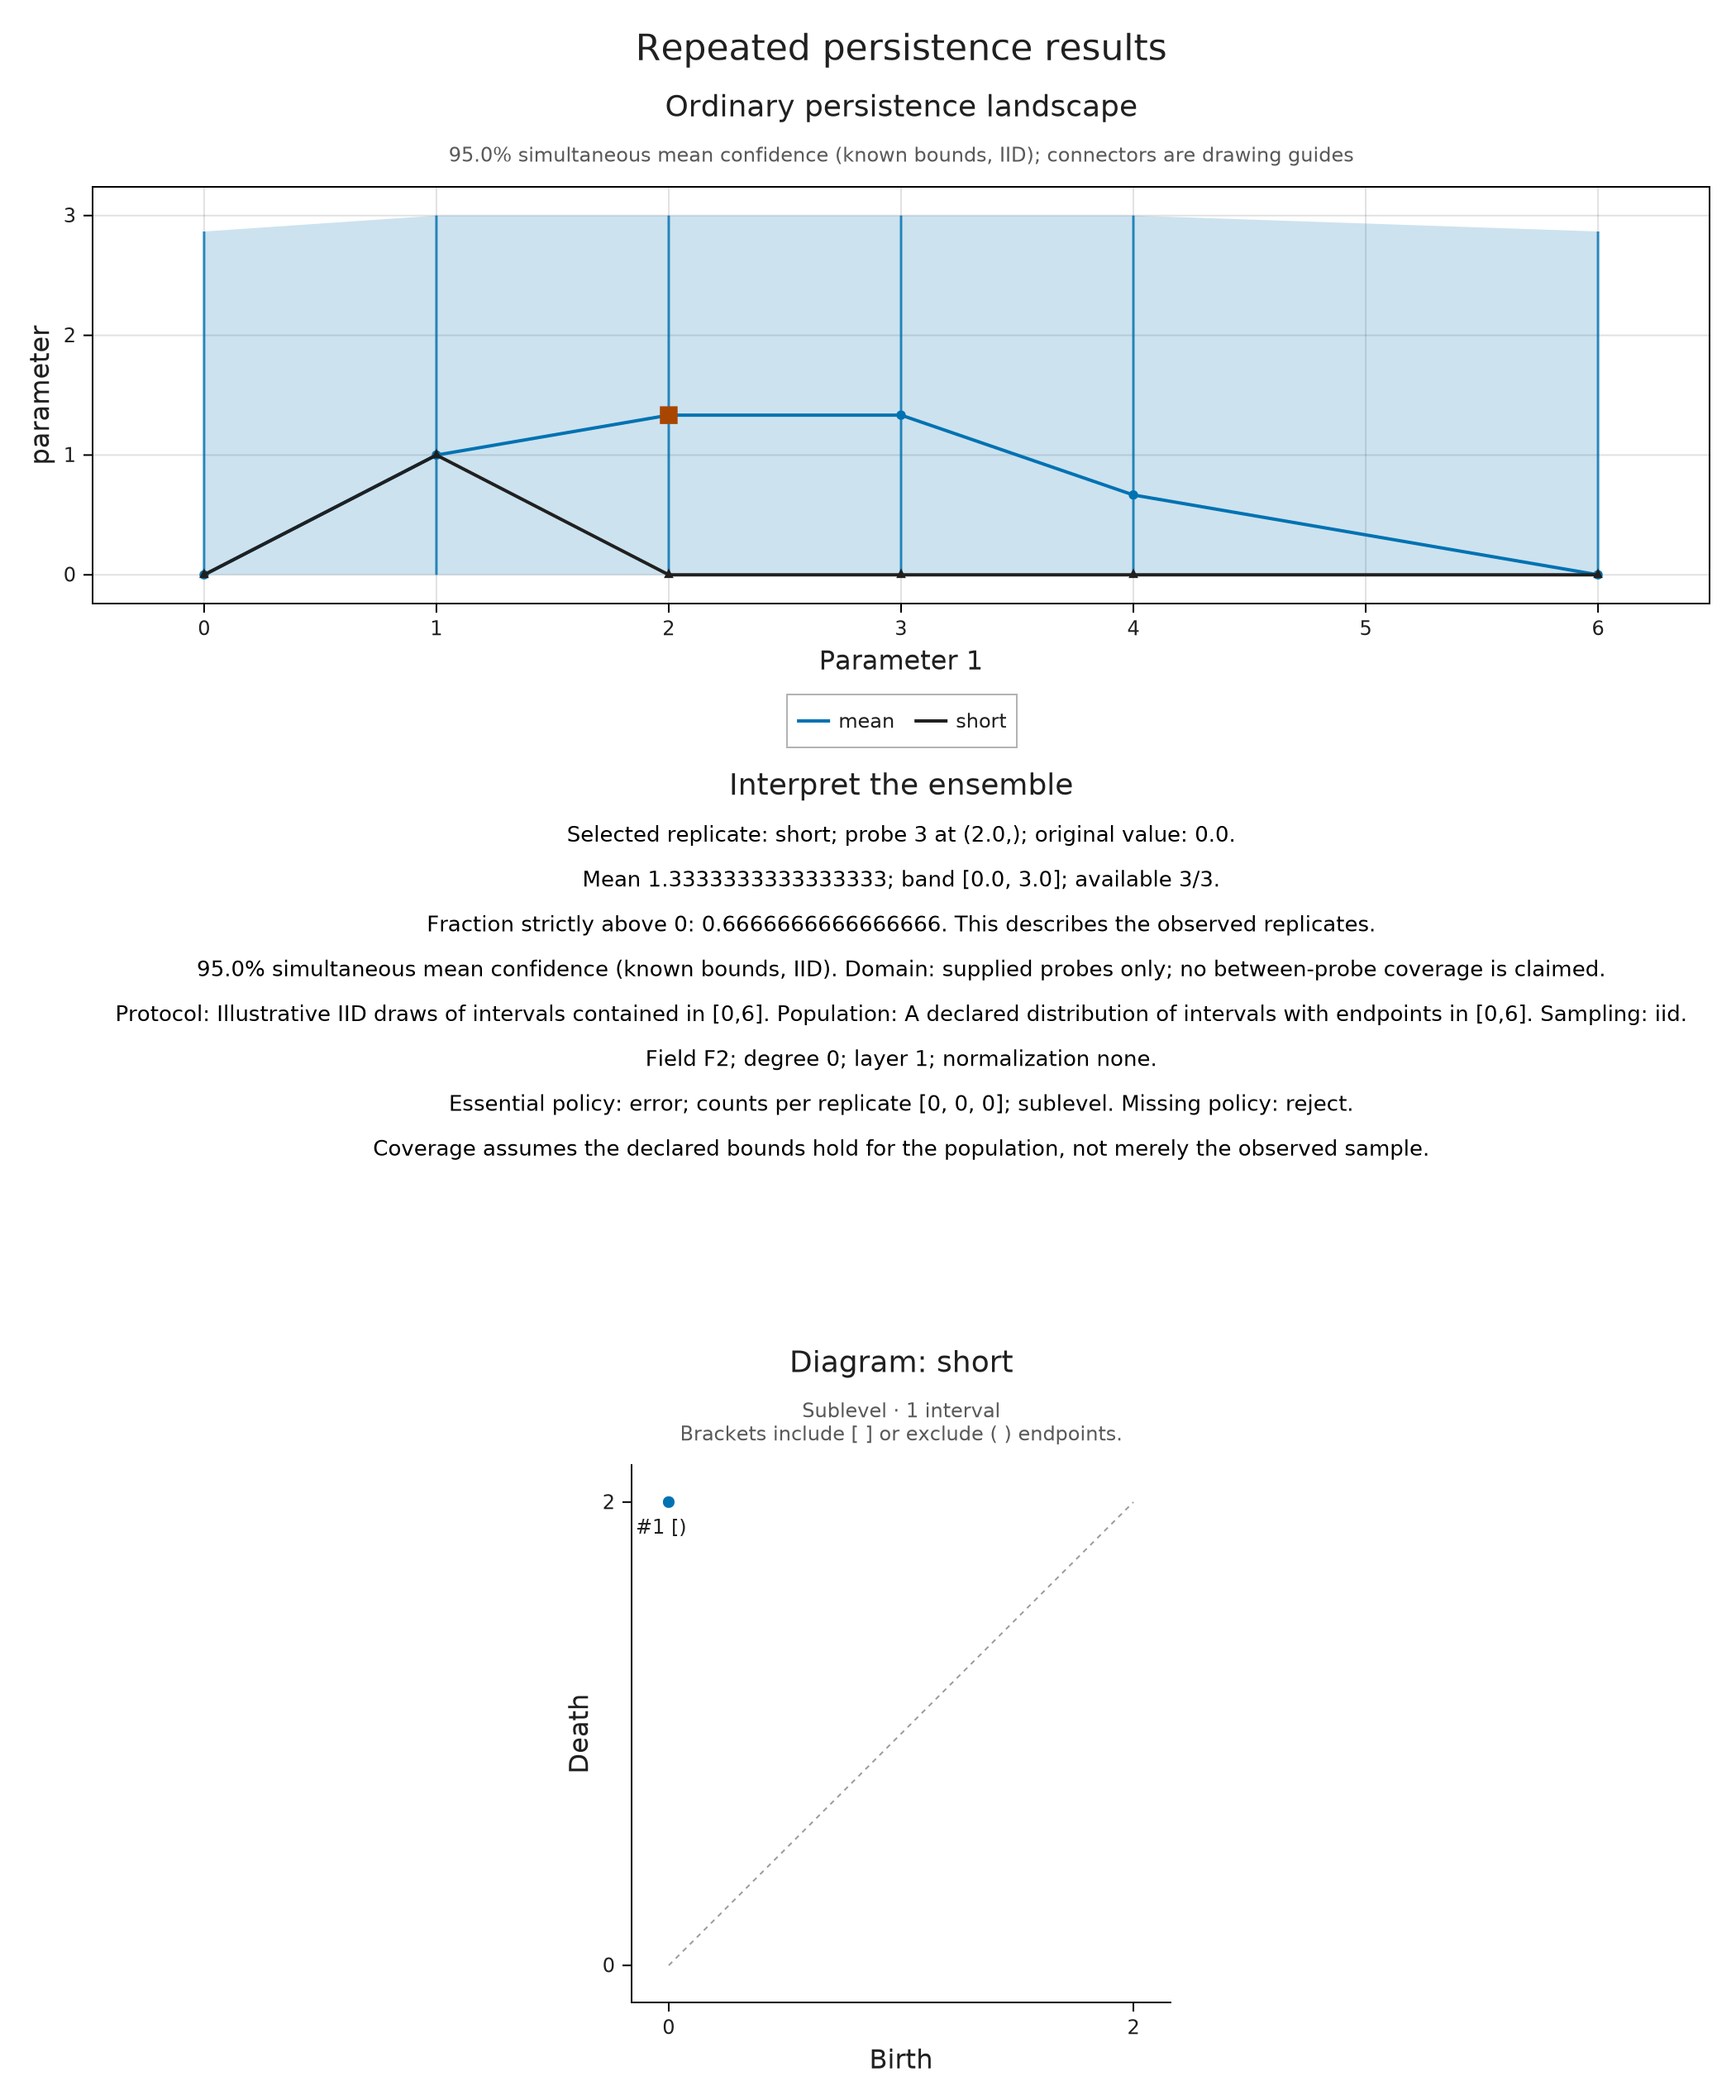

In [9]:
iid_ensemble = persistence_ensemble(diagrams; grid=[0.,1.,2.,3.,4.,6.],
    sample_ids=["short","middle","long"], sampling=:iid,
    protocol="Illustrative IID draws of intervals contained in [0,6]",
    population="A declared distribution of intervals with endpoints in [0,6]")
confidence = summarize_ensemble(iid_ensemble; band=:hoeffding, bounds=(0,3), level=0.95)
visualize(confidence; probe=3)

The wide band reflects how little three observations tell us about a population. Hoeffding's inequality and a union bound give simultaneous coverage over the six probes, conditional on the stated hypotheses. `scope=:pointwise` instead protects each probe separately at the requested level; it does not give that level for all probes together. Neither band is a confidence set for a persistence module.

A whole-row bootstrap offers an approximate alternative without known bounds. Resampling whole rows preserves dependence among values at different probes. It has no finite-sample coverage certificate; tiny, degenerate, dependent or adaptively selected samples can make it misleading. The seed and number of resamples are retained.


In [10]:
bootstrap = summarize_ensemble(iid_ensemble; band=:bootstrap,
    bootstrap_samples=500, seed=27, scope=:simultaneous)
@assert ensemble_summary(bootstrap).contract.coverage == :approximate
ensemble_summary(bootstrap)

(kind = :ensemble_summary, ensemble = (kind = :persistence_ensemble, samples = 3, probes = 6, shape = (6,), context = (statistic = "Ordinary persistence landscape", protocol = "Illustrative IID draws of intervals contained in [0,6]", population = "A declared distribution of intervals with endpoints in [0,6]", sampling = :iid, units = "parameter", axis_labels = ("Parameter 1",), degree = 0, field = "TamerOp.CoreModules.CoeffFields.PrimeField(2)", layer = 1, normalization = "none", essential = "error; counts per replicate [0, 0, 0]; sublevel"), missing = 0), contract = (band = :bootstrap, quantiles = (0.1, 0.9), threshold = 0, level = 0.95, scope = :simultaneous, coverage = :approximate, domain = :supplied_probes_only, bounds = nothing, bootstrap_samples = 500, seed = 27, missing_policy = :reject))

## Select a replicate and its source

Prepared summaries can share a live selection across views. Retained source specifications follow the same replicate IDs; supplying them declares their relationship to the measurements. Selecting a probe or replicate never recomputes the inference. Here a static snapshot demonstrates the same selected data that the live inspector uses.


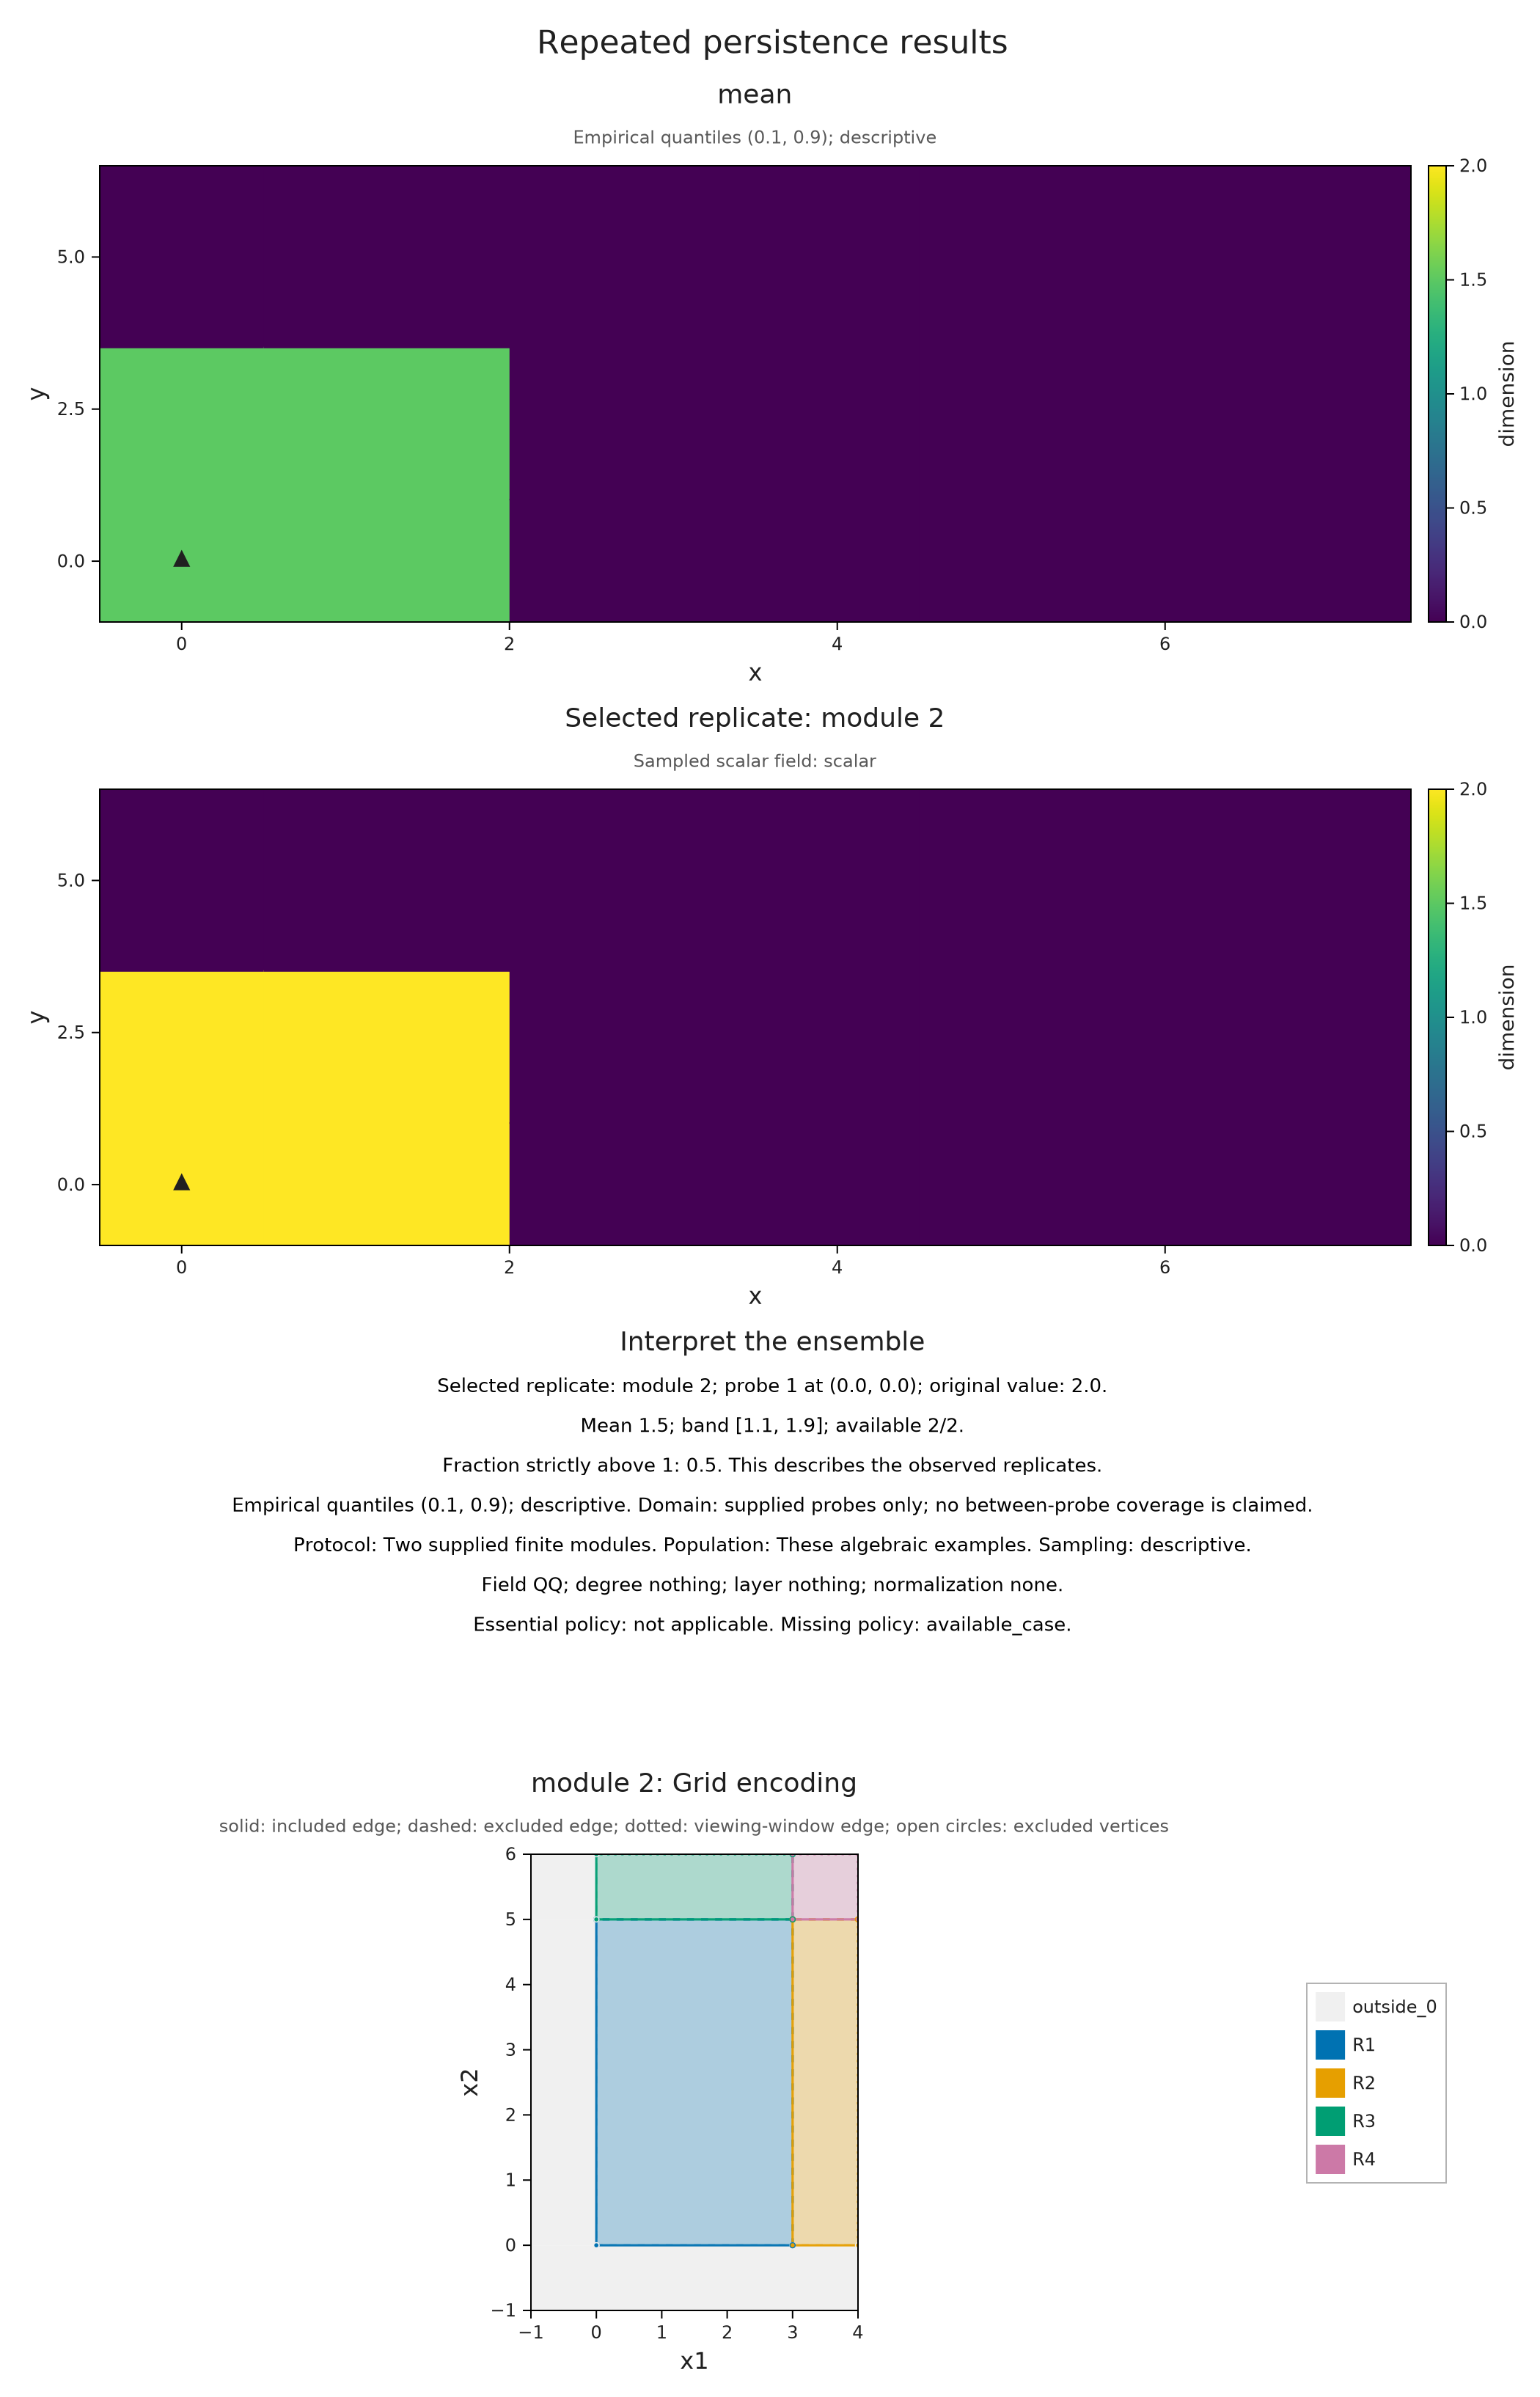

In [11]:
sources = [(source=V.visual_spec(enc),) for enc in encoded]
session = inspection_session(module_spread; samples=sources)
A.select_inspection!(session; sample="module 2", probe=1)
visualize(A.inspection_snapshot(session))

For a live Julia session, import WGLMakie and call `visualize(session; backend=:wglmakie)`. Pointer picking and labelled replicate/probe inputs select the same data. Invalid selections leave the last valid view intact. Static HTML exports retain a prepared figure, not these Julia callbacks; notebook hosts have their own frontend requirements.

### Optional: keep a figure and release the session

Use the usual export path. The snapshot survives closing; the session releases its input references and listeners. The [API reference](../src/reference/ensembles.md) specifies shape, missing-data, essential-feature and inference contracts. [Aligned ensembles and uncertainty computations](../implementation/ensembles.md) explains the algorithms and costs.


In [12]:
snapshot = A.inspection_snapshot(session)
A.close_inspection!(session)
@assert A.check_inspection_session(session).valid

The workflow ends with a clearly defined observable, a common probe domain, and a summary whose interpretation follows from how the repeats were obtained. For comparisons that do not share a sampling population, continue with [declared correspondences](comparisons.ipynb).
